# Predicting category switching

## 1. Project overview

### 1.1 Business problem
An e-commerce website could use browsing behavior to decide whether to keep showing
products from the current category or introduce products from other categories.
This notebook predicts category switching. It does not build a complete recommendation system.

### 1.2 Research question
> Can users' current and historical browsing behavior help predict whether they will switch to another product category on their next click?

- **RQ1:** How well can current browsing information predict category switching?
- **RQ2:** Does adding browsing history improve switch prediction?

### 1.3 Target and prediction time
Predict **after the current click has been recorded and before the next click**.
Given that another click occurs in the same session, will its product category stay the same?

- `switch_category = 0` (**Stay**): the next click has the current category.
- `switch_category = 1` (**Switch**): the next click has a different category.

The final click of each session has no observed next category, so it has no label and is excluded from the modeling dataset. The label uses the next click only during training and evaluation. It is unavailable when a prediction is made. This model does not predict whether a user will end the session.

**Switch = 1 is the positive class and the business-interest class.** We compare **Current** with **Current + History** on the same labeled clicks and session split.

## 2. Data understanding

### 2.1 Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display


from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score
)

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", 14)

### 2.2 Load dataset


In [3]:
df = pd.read_csv("e-shop clothing 2008.csv")
display(df.head())
print("Rows and columns:", df.shape)
print("Column names:", df.columns.tolist())

,year,month,day,order,country,session ID,page 1 (main category),page 2 (clothing model),colour,location,model photography,price,price 2,page
0,2008,4,1,1,29,1,1,A13,1,5,1,28,2,1
1,2008,4,1,2,29,1,1,A16,1,6,1,33,2,1
2,2008,4,1,3,29,1,2,B4,10,2,1,52,1,1
3,2008,4,1,4,29,1,2,B17,6,6,2,38,2,1
4,2008,4,1,5,29,1,2,B8,4,3,2,52,1,1


Rows and columns: (165474, 14)
Column names: ['year', 'month', 'day', 'order', 'country', 'session ID', 'page 1 (main category)', 'page 2 (clothing model)', 'colour', 'location', 'model photography', 'price', 'price 2', 'page']


### 2.3 Dataset structure

The local `e-shop clothing 2008 data description.txt` defines all 14 original columns:

| Variable | Meaning |
| --- | --- |
| `year`, `month`, `day` | Date of the click; all records are from 2008 |
| `order` | Click position within a session |
| `country` | Country inferred from the IP address, not necessarily the shopper's residence |
| `session ID` | Browsing session identifier, not a known customer identity |
| `page 1 (main category)` | 1 = Trousers, 2 = Skirts, 3 = Blouses, 4 = Sale |
| `page 2 (clothing model)` | Product code |
| `colour` | Product colour code |
| `location` | Product photo position in one of six screen areas |
| `model photography` | Front or profile view |
| `price` | Current product price in US dollars |
| `price 2` | Whether price is above the product category average |
| `page` | Catalogue page number, from 1 to 5 |

The data cover April to August 2008. A click records browsing, not a purchase.

### 2.4 Basic data quality checks

In [5]:
df.info()
display(df.isna().sum().rename("Missing values").to_frame())
print("Duplicate rows:", df.duplicated().sum())
print("Sessions:", df["session ID"].nunique())
print("Clothing models:", df["page 2 (clothing model)"].nunique())

assert not df.isna().any().any()
assert not df.duplicated().any()
assert not df.duplicated(["session ID", "order"]).any()
assert set(df["page 1 (main category)"]) == {1, 2, 3, 4}

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 165474 entries, 0 to 165473
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype 
---  ------                   --------------   ----- 
 0   year                     165474 non-null  int64 
 1   month                    165474 non-null  int64 
 2   day                      165474 non-null  int64 
 3   order                    165474 non-null  int64 
 4   country                  165474 non-null  int64 
 5   session ID               165474 non-null  int64 
 6   page 1 (main category)   165474 non-null  int64 
 7   page 2 (clothing model)  165474 non-null  object
 8   colour                   165474 non-null  int64 
 9   location                 165474 non-null  int64 
 10  model photography        165474 non-null  int64 
 11  price                    165474 non-null  int64 
 12  price 2                  165474 non-null  int64 
 13  page                     165474 non-null  int64 
dtypes: int64(13), object

,Missing values
year,0
month,0
day,0
order,0
country,0
session ID,0
page 1 (main category),0
page 2 (clothing model),0
colour,0
location,0


Duplicate rows: 0
Sessions: 24026
Clothing models: 217


The dataset contains 165,474 clicks across 24,026 sessions, with no missing values or duplicate records.

## 3. Target and feature construction

The next click creates a label after the fact; it is never available as a model
input. First sort clicks within each session, then build the target and features.

### 3.1 Target construction
Keep only clicks with an observed next click. This prevents a final click,
whose next category is missing, from being temporarily labeled Switch.

In [6]:
df = df.sort_values(["session ID", "order"]).copy()
df["next_category"] = df.groupby("session ID")["page 1 (main category)"].shift(-1)
df_model = df[df["next_category"].notna()].copy()
df_model["switch_category"] = (
    df_model["next_category"] != df_model["page 1 (main category)"]
).astype(int)

print("Raw clicks:", len(df))
print("Removed final clicks:", len(df) - len(df_model))
print("Rows with a target:", len(df_model))

Raw clicks: 165474


Removed final clicks: 24026


Rows with a target: 141448


### 3.2 Historical features

- `prev_category`: previous category; 0 means no previous click.
- `same_category_prev`: -1 = no previous click, 0 = different, 1 = same.
- `category_visit_count`: visits to the current category **before** this click.

The first occurrence has count 0. `cumcount()` excludes the current and later
clicks; a final session total would leak future information.

In [7]:
df_model["prev_category"] = (
    df_model.groupby("session ID")["page 1 (main category)"].shift(1)
).fillna(0).astype(int)
df_model["same_category_prev"] = np.where(
    df_model["prev_category"] == 0,
    -1,
    (df_model["prev_category"] == df_model["page 1 (main category)"]).astype(int)
)
df_model["category_visit_count"] = (
    df_model.groupby(["session ID", "page 1 (main category)"]).cumcount()
)
print("Retained first clicks:", df_model["prev_category"].eq(0).sum())

Retained first clicks: 18984


### 3.3 Sequence validation
Inspect session 1 to check that the label and historical features follow click order.

In [9]:
example_columns = [
    "session ID", "order", "page 1 (main category)", "prev_category",
    "same_category_prev", "category_visit_count", "next_category", "switch_category"
]
display(df_model.loc[df_model["session ID"].isin([1]), example_columns])

,session ID,order,page 1 (main category),prev_category,same_category_prev,category_visit_count,next_category,switch_category
0,1,1,1,0,-1,0,1.0,0
1,1,2,1,1,1,1,2.0,1
2,1,3,2,1,0,0,2.0,0
3,1,4,2,2,1,1,2.0,0
4,1,5,2,2,1,2,3.0,1
5,1,6,3,2,0,0,3.0,0
6,1,7,3,3,1,1,4.0,1
7,1,8,4,3,0,0,4.0,0


In session 1, click 1 has no previous category and zero earlier visits. Click 2 has
one earlier visit to Trousers and switches next to Skirts. On click 3, the earlier
visit count for Skirts is zero. The removed final click still supplies the next
category for the preceding row.

## 4. Train/test split by session

`GroupShuffleSplit` assigns whole sessions to one 80/20 train/test split. Here,
20% refers to sessions; test has 3,797 of 18,984 eligible sessions and 28,957
of 141,448 labeled clicks (20.47%). No session appears in both sets, though
different sessions may belong to the same unknown person.

In [10]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_index, test_index = next(
    splitter.split(df_model, groups=df_model["session ID"])
)
train_df = df_model.iloc[train_index].copy()
test_df = df_model.iloc[test_index].copy()
train_sessions = train_df["session ID"].unique()
test_sessions = test_df["session ID"].unique()

assert set(train_sessions).isdisjoint(set(test_sessions))
print("Train rows / sessions:", len(train_df), len(train_sessions))
print("Test rows / sessions:", len(test_df), len(test_sessions))
print("Overlapping sessions:", len(set(train_sessions) & set(test_sessions)))

Train rows / sessions: 112491 15187
Test rows / sessions: 28957 3797
Overlapping sessions: 0


## 5. Exploratory data analysis
All EDA below uses **training clicks with an observed next click**. Each group
table reports its click count as well as its switch rate, because small groups
can have unstable rates. Clicks from the same session are related, and longer
sessions contribute more clicks. These are descriptive associations, not causal
effects or test-set performance.

### 5.1 Target distribution

,Count,Share (%)
switch_category,,
Stay,91257,81.12
Switch,21234,18.88


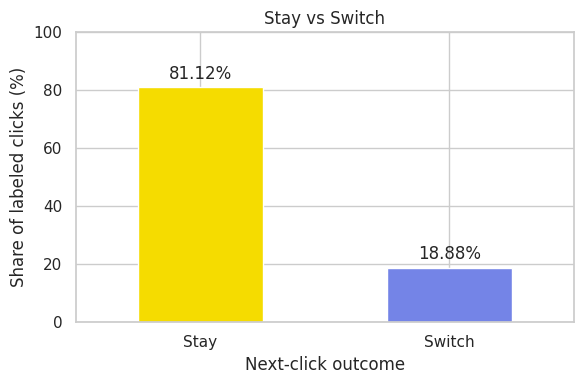

In [13]:
target_counts = train_df["switch_category"].value_counts().reindex([0, 1])
target_summary = pd.DataFrame({
    "Count": target_counts,
    "Share (%)": 100 * target_counts / target_counts.sum()
}).rename(index={0: "Stay", 1: "Switch"})
display(target_summary.round(2))

ax = target_summary["Share (%)"].plot.bar(rot=0, color=["#F5DC00", "#7484E7"], figsize=(6, 4))
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)
ax.set(title="Stay vs Switch", xlabel="Next-click outcome", ylabel="Share of labeled clicks (%)", ylim=(0, 100))
plt.tight_layout()
plt.show()

Switch represents 18.88% of training clicks. Always predicting Stay can therefore
look accurate while missing every switch. We need Switch precision, recall, and F1
to evaluate detection of the minority class.

### 5.2 Switch rate by current category

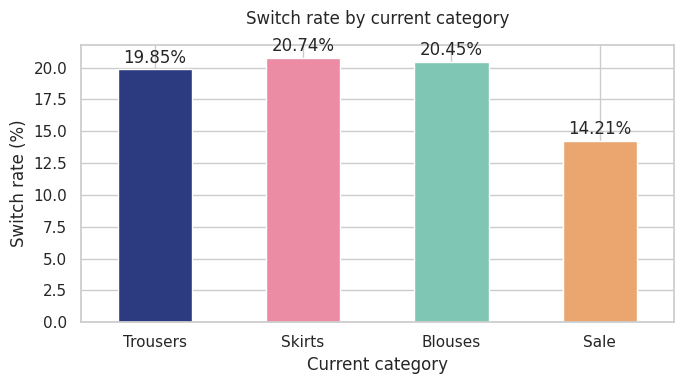

In [14]:
category_names = {1: "Trousers", 2: "Skirts", 3: "Blouses", 4: "Sale"}
category_rates = train_df.groupby("page 1 (main category)")["switch_category"].agg(
    ["size", "mean"]
).rename(index=category_names, columns={"size": "Clicks", "mean": "Switch rate"})
ax = (100 * category_rates["Switch rate"]).plot.bar(rot=0, color = ["#2C3A80", "#EB8BA4", "#7FC7B4", "#EBA56F"], figsize=(7, 4))
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=2)
ax.set_title("Switch rate by current category", pad=15)
ax.set(xlabel="Current category", ylabel="Switch rate (%)")
plt.tight_layout()
plt.show()

Sale has a switch rate of 14.21%,
compared with 20.74% for Skirts. This variation supports
retaining current category. It describes an association, not an effect caused by the category.

### 5.3 Switch rate by browsing position

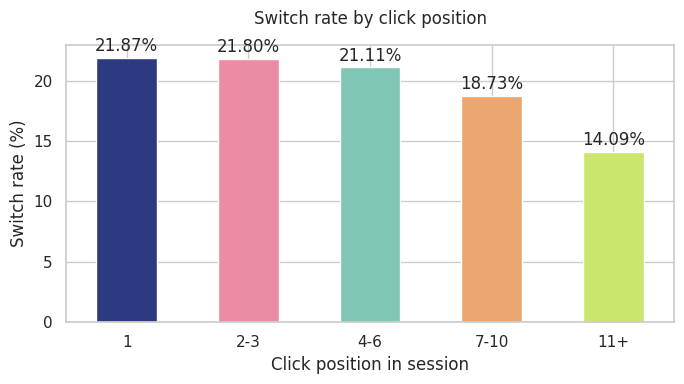

In [15]:
order_groups = pd.cut(
    train_df["order"], bins=[0, 1, 3, 6, 10, np.inf],
    labels=["1", "2-3", "4-6", "7-10", "11+"]
)
order_rates = train_df.groupby(order_groups, observed=True)["switch_category"].agg(
    ["size", "mean"]
)
ax = (100 * order_rates["mean"]).plot.bar(rot=0, color = ["#2C3A80", "#EB8BA4", "#7FC7B4", "#EBA56F", "#CAE66D"], figsize=(7, 4))
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=2)
ax.set_title("Switch rate by click position", pad=15)
ax.set(xlabel="Click position in session", ylabel="Switch rate (%)")
plt.tight_layout()
plt.show()

The switch rate falls from 21.87% at the first click
to 14.09% at positions 11 and later. Retain `order` as current context.
This comparison also reflects which sessions continue long enough to reach later positions.

### 5.4 Switch rate by recent category consistency

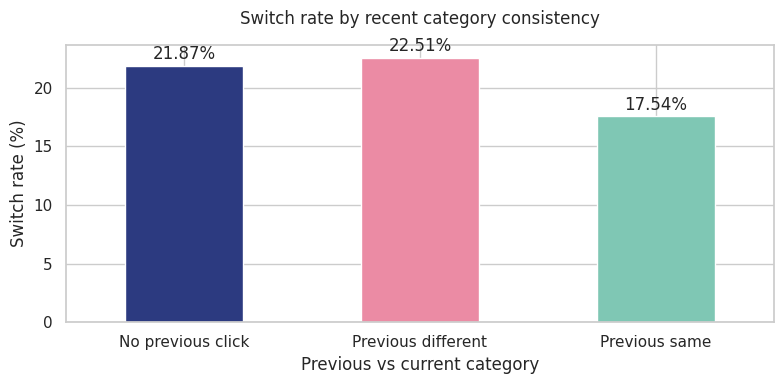

In [16]:
history_labels = {-1: "No previous click", 0: "Previous different", 1: "Previous same"}
consistency_rates = train_df.groupby("same_category_prev")["switch_category"].agg(
    ["size", "mean"]
).rename(index=history_labels)
ax = (100 * consistency_rates["mean"]).plot.bar(rot=0, color = ["#2C3A80", "#EB8BA4", "#7FC7B4"], figsize=(8, 4))
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=2)
ax.set_title("Switch rate by recent category consistency", pad=15)
ax.set(xlabel="Previous vs current category", ylabel="Switch rate (%)")
plt.tight_layout()
plt.show()

Switching is 22.51% after a different category, 17.54% after the same category, and
21.87% on first clicks. Recent consistency may help; the model comparison will test
whether it adds value beyond current information.

### 5.5 Switch rate by category visit count

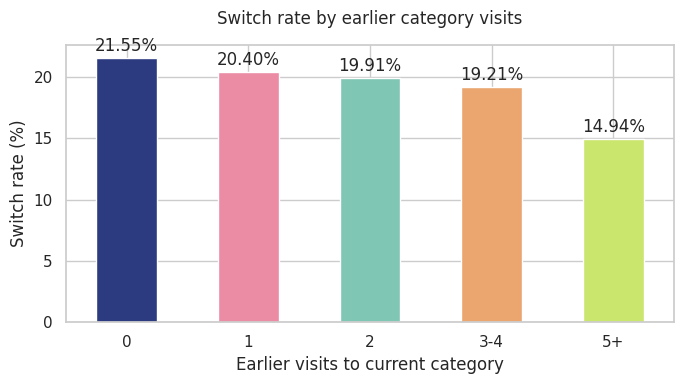

In [17]:
visit_groups = pd.cut(
    train_df["category_visit_count"], bins=[-1, 0, 1, 2, 4, np.inf],
    labels=["0", "1", "2", "3-4", "5+"]
)
visit_rates = train_df.groupby(visit_groups, observed=True)["switch_category"].agg(
    ["size", "mean"]
)
ax = (100 * visit_rates["mean"]).plot.bar(rot=0, color = ["#2C3A80", "#EB8BA4", "#7FC7B4", "#EBA56F", "#CAE66D"], figsize=(7, 4))
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=2)
ax.set_title("Switch rate by earlier category visits", pad=15)
ax.set(xlabel="Earlier visits to current category", ylabel="Switch rate (%)")
plt.tight_layout()
plt.show()

Switching falls from 21.55% with no earlier category visit to 14.94% with five or more.
Repeated interest may help prediction, but it overlaps with session position.

### 5.6 Previous and current category

Current category   Trousers  Skirts  Blouses   Sale
Previous category                                  
Trousers              24312    2102     2099   1282
Skirts                 1297   17700     1997   1026
Blouses                1397    1106    18536   1724
Sale                   1008     933     1011  19774

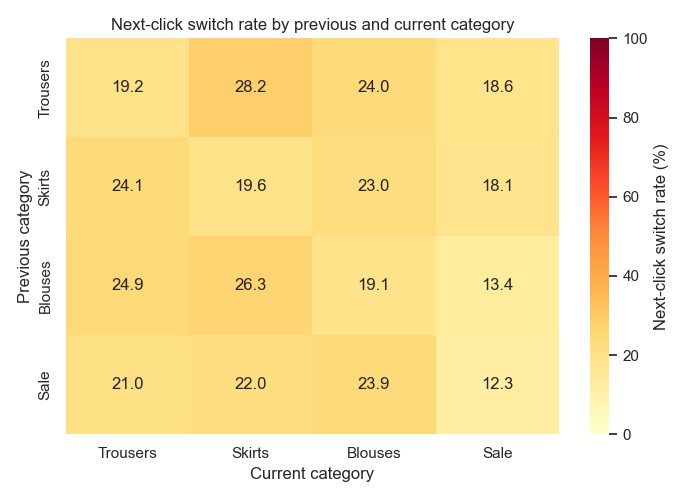

In [18]:
past_clicks = train_df[train_df["prev_category"] != 0]
transition_rates = past_clicks.pivot_table(
    index="prev_category", columns="page 1 (main category)",
    values="switch_category", aggfunc="mean"
).rename(index=category_names, columns=category_names)
transition_counts = past_clicks.pivot_table(
    index="prev_category", columns="page 1 (main category)",
    values="switch_category", aggfunc="size"
).rename(index=category_names, columns=category_names)
display(transition_counts.rename_axis(index="Previous category", columns="Current category"))
plt.figure(figsize=(7, 5))
sns.heatmap(100 * transition_rates, annot=True, fmt=".1f", cmap="YlOrRd",
            vmin=0, vmax=100, cbar_kws={"label": "Next-click switch rate (%)"})
plt.title("Next-click switch rate by previous and current category")
plt.xlabel("Current category")
plt.ylabel("Previous category")
plt.tight_layout()
plt.show()

For clicks with previous Trousers and current Skirts, 28.2% switch **on
the next click**. This is not the probability of moving from Trousers to Skirts.
First clicks are excluded; every displayed pair has at least 933 observations.

### 5.7 Price and switching

,median,mean
switch_category,,
Stay,43.0,43.65
Switch,43.0,44.25


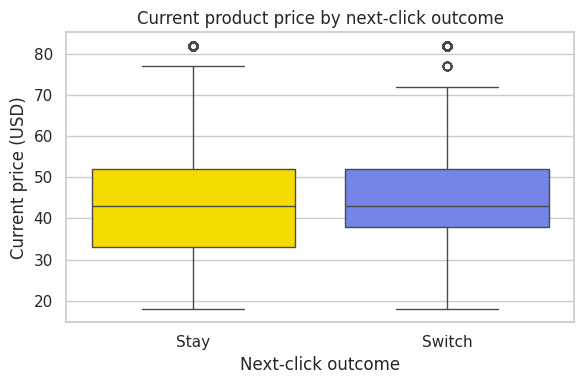

In [19]:
price_summary = train_df.groupby("switch_category")["price"].agg(["median", "mean"])
display(price_summary.rename(index={0: "Stay", 1: "Switch"}).round(2))
plt.figure(figsize=(6, 4))
sns.boxplot(data=train_df, x="switch_category", y="price", order=[0, 1], hue="switch_category", palette={0: "#F5DC00", 1: "#7484E7"}, saturation=1, legend=False)
plt.xticks([0, 1], ["Stay", "Switch"])
plt.title("Current product price by next-click outcome")
plt.xlabel("Next-click outcome")
plt.ylabel("Current price (USD)")
plt.tight_layout()
plt.show()

Both groups have a median price of $43, and their distributions overlap strongly.
Price alone does not clearly separate Stay and Switch. Keep it in the specified
current feature set to evaluate it alongside other inputs.

### 5.8 Catalogue page and switching

,Clicks,Switch rate
page,,
1,63833,0.178
2,28181,0.179
3,13014,0.219
4,5809,0.255
5,1654,0.282


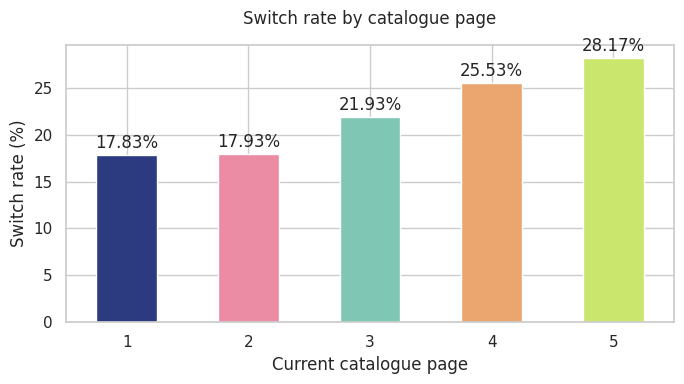

In [20]:
page_rates = train_df.groupby("page")["switch_category"].agg(["size", "mean"])
display(page_rates.rename(columns={"size": "Clicks", "mean": "Switch rate"}).round(3))
ax = (100 * page_rates["mean"]).plot.bar(rot=0, color = ["#2C3A80", "#EB8BA4", "#7FC7B4", "#EBA56F", "#CAE66D"], figsize=(7, 4))
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=2)
ax.set_title("Switch rate by catalogue page", pad=15)
ax.set(xlabel="Current catalogue page", ylabel="Switch rate (%)")
plt.tight_layout()
plt.show()

The switch rate rises from 17.83% on page 1 to
28.17% on page 5. Page 5 has only 1,654 observations,
compared with 63,833 on page 1. Retain catalogue page, while recognizing
that these pages may contain different categories and products.

### 5.9 Country
The IP-derived country code is unevenly represented. The table shows the ten
largest groups; the count below reports sparse groups.

In [21]:
def group_switch_summary(feature):
    summary = train_df.groupby(feature)["switch_category"].agg(["size", "mean"])
    summary = summary.rename(columns={"size": "Clicks", "mean": "Switch rate (%)"})
    summary["Share (%)"] = 100 * summary["Clicks"] / len(train_df)
    summary["Switch rate (%)"] *= 100
    return summary[["Clicks", "Share (%)", "Switch rate (%)"]]

country_summary = group_switch_summary("country").sort_values("Clicks", ascending=False)
display(country_summary.head(10).round(2))
print("Country groups:", len(country_summary))
print("Groups with fewer than 100 clicks:", (country_summary["Clicks"] < 100).sum())
print("Clicks in groups with fewer than 100:", country_summary.loc[country_summary["Clicks"] < 100, "Clicks"].sum())

         Clicks  Share (%)  Switch rate (%)
country                                    
29        91157      81.03            19.18
9         12212      10.86            14.88
24         2837       2.52            19.84
46         1545       1.37            27.44
44          894       0.79            24.61
16          673       0.60            12.04
21          621       0.55            18.68
34          461       0.41            15.40
41          441       0.39            23.58
3           155       0.14            12.90

Country groups: 40
Groups with fewer than 100 clicks: 25
Clicks in groups with fewer than 100: 824


Country code 29 supplies 81.03% of training clicks; 25 of the 40
observed codes have fewer than 100 clicks each. **Exclude country** from this
browsing-behavior comparison and treat small-group rates cautiously.

### 5.10 Product and presentation attributes
These tables show the size and switch rate of each `colour`, `location`,
`model photography`, and `price 2` group.

In [22]:
colour_summary = group_switch_summary("colour").sort_values("Clicks", ascending=False)
location_summary = group_switch_summary("location").sort_values("Clicks", ascending=False)
photography_summary = group_switch_summary("model photography")
price2_summary = group_switch_summary("price 2")

print("Colour")
display(colour_summary.round(2))
print("Location")
display(location_summary.round(2))
print("Model photography")
display(photography_summary.round(2))
print("Price 2")
display(price2_summary.round(2))

Colour


        Clicks  Share (%)  Switch rate (%)
colour                                    
2        20313      18.06            17.87
3        20129      17.89            17.05
6        11604      10.32            23.66
4        11274      10.02            17.34
14       10703       9.51            20.31
9         9198       8.18            17.45
12        6003       5.34            17.44
1         5447       4.84            17.55
7         4639       4.12            19.59
13        4188       3.72            21.51
11        3583       3.19            17.97
10        2432       2.16            28.25
8         1898       1.69            11.01
5         1080       0.96            31.30

Location


          Clicks  Share (%)  Switch rate (%)
location                                    
1          23623      21.00            18.95
2          22333      19.85            21.60
5          18959      16.85            18.60
4          18737      16.66            16.55
3          14788      13.15            16.92
6          14051      12.49            19.95

Model photography


                   Clicks  Share (%)  Switch rate (%)
model photography                                    
1                   83592      74.31            18.50
2                   28899      25.69            19.96

Price 2


         Clicks  Share (%)  Switch rate (%)
price 2                                    
1         57401      51.03            19.01
2         55090      48.97            18.74

Colour rates range from 11.01% to 31.30%, but category and
product choice may confound the pattern. Location rates range from 16.55% to
21.60%. Front-view and profile-view photography differ only slightly (18.50%
versus 19.96%). **Keep** these three current-product attributes for joint
validation; these tables cannot establish independent predictive value.

`price 2` has two similarly sized groups and close switch rates (19.01% and
18.74%). **Exclude it** from the compact comparison; its extra predictive
value has not been tested.

### 5.11 Numeric correlation and group sizes
Check the four numeric inputs and the most uneven sample sizes. Category codes
are not treated as continuous numbers in the correlation table.

In [23]:
numeric_features = ["order", "price", "page", "category_visit_count"]
display(train_df[numeric_features].corr().round(3))

size_audit = pd.DataFrame({
    name: {"Smallest group": counts.min(), "Largest group": counts.max()}
    for name, counts in {
        "Country": train_df.groupby("country").size(),
        "Colour": train_df.groupby("colour").size(),
        "Catalogue page": train_df.groupby("page").size(),
    }.items()
}).T
display(size_audit)

                      order  price   page  category_visit_count
order                 1.000 -0.069  0.218                 0.745
price                -0.069  1.000 -0.155                -0.045
page                  0.218 -0.155  1.000                 0.268
category_visit_count  0.745 -0.045  0.268                 1.000

                Smallest group  Largest group
Country                      1          91157
Colour                    1080          20313
Catalogue page            1654          63833

`order` and `category_visit_count` correlate most strongly (Pearson
**0.745**): later clicks allow more earlier category visits. They describe
different behavior, so correlation alone does not decide whether to keep
either feature. Country has one-click groups and catalogue page ranges from
1,654 to 63,833 clicks. Group rates describe related clicks, not independent
shoppers, and small-group rates need caution.

## 6. Feature selection and availability

Predict just after the current click is recorded. The seven **Current** inputs
describe that click; **Current + History** adds information from the current
and earlier clicks. Both experiments use the same labeled rows and session
split. The offline data do not establish live logging latency.

| Feature set | Inputs | Available at prediction time |
| --- | --- | --- |
| Current | `page 1 (main category)`, `order`, `price`, `colour`, `location`, `model photography`, `page` | Recorded for the current click |
| Current + History | All Current inputs, plus `prev_category`, `same_category_prev`, `category_visit_count` | Previous clicks and current category are known; visit count excludes the current click |

### Feature decisions
This is a compact feature-set design for the research question, not a ranking
of individual feature importance. EDA does not prove that `colour` predicts
better than `country`; added value needs validation.

| Feature | Decision | Reason |
| --- | --- | --- |
| `page 1 (main category)` | Keep, Current | Defines the current state; four reasonably sized groups have different switch rates. |
| `order` | Keep, Current | Available click position; rates vary by position. Correlation with visit count is not a selection rule. |
| `price` | Keep, Current | Available product attribute; overlapping Stay/Switch distributions warrant joint testing. |
| `colour` | Keep, Current | Available product attribute; all 14 groups have at least 1,080 training clicks. |
| `location` | Keep, Current | Available photo placement; six reasonably sized groups. |
| `model photography` | Keep, Current | Available photo style; both groups are represented despite a small rate difference. |
| `page` | Keep, Current | Available catalogue context; rates vary, with a smaller page-5 group. |
| `prev_category` | Keep, History | Previous click is known and records the earlier category; first clicks use code 0. |
| `same_category_prev` | Keep, History | Direct same/different representation may help a linear model, though it can be derived from previous and current category; first clicks use code -1. |
| `category_visit_count` | Keep, History | Strictly prior visits to the current category capture repeat interest. |
| `country` | Exclude | Outside the browsing-behavior question; code 29 supplies 81.03% of training clicks and many groups are sparse. |
| `page 2 (clothing model)` | Exclude | 217 product codes add high-cardinality identity outside the compact Current set. |
| `price 2` | Exclude | Category-relative price is outside the compact Current set; its groups have close switch rates, but extra predictive value remains untested. |
| `year` | Exclude | Constant at 2008. |
| `month`, `day` | Exclude | Calendar effects are outside this behavioral question and need separate temporal evaluation. |
| `session ID` | Exclude | Group and split identifier, not a transferable predictor. |
| `next_category` | Exclude | Future information used only to create the label. |
| `switch_category` | Target | The answer being predicted, never an input. |

No feature is selected solely by correlation, and no input uses the next or
later click. Independent predictive value remains a validation question.

In [11]:
current_features = [
    "page 1 (main category)", "order", "price", "colour",
    "location", "model photography", "page"
]
current_history_features = current_features + [
    "prev_category", "same_category_prev", "category_visit_count"
]

current_categorical = [
    "page 1 (main category)", "colour", "location", "model photography"
]
current_numerical = ["order", "price", "page"]
history_categorical = current_categorical + ["prev_category", "same_category_prev"]
history_numerical = current_numerical + ["category_visit_count"]

Treat category codes as categories, including the three states of
`same_category_prev`. Treat `order`, `price`, `page`, and the visit count as
numerical. The visit count is strictly prior history: a first visit to the
current category has count 0. The table above records the reason for every
included or excluded dataset column and engineered feature.

In [39]:
X_train_current = train_df[current_features]
X_test_current = test_df[current_features]
X_train_history = train_df[current_history_features]
X_test_history = test_df[current_history_features]
y_train = train_df["switch_category"]
y_test = test_df["switch_category"]

print("Current features:", len(current_features))
print("Current + history features:", len(current_history_features))

# Target distribution in train and test sets
target_distribution = pd.DataFrame({
    "Train Count": y_train.value_counts().reindex([0, 1], fill_value=0),
    "Train (%)": y_train.value_counts(normalize=True).reindex([0, 1], fill_value=0) * 100,
    "Test Count": y_test.value_counts().reindex([0, 1], fill_value=0),
    "Test (%)": y_test.value_counts(normalize=True).reindex([0, 1], fill_value=0) * 100
})

target_distribution.index = ["Stay (0)", "Switch (1)"]

display(target_distribution.round(2))

Current features: 7
Current + history features: 10


,Train Count,Train (%),Test Count,Test (%)
Stay (0),91257,81.12,23666,81.73
Switch (1),21234,18.88,5291,18.27


In [45]:
print(X_train_current.shape)
print(X_test_current.shape)
print(X_train_history.shape)
print(X_test_history.shape)
print(y_train.shape)
print(y_test.shape)

(112491, 7)
(28957, 7)
(112491, 10)
(28957, 10)
(112491,)
(28957,)


## 7. Model development

### 7.1 Preprocessing

In [47]:
RANDOM_STATE = 42
excluded_cols = {"session ID", "next_category", "switch_category"}
assert excluded_cols.isdisjoint(current_features)
assert excluded_cols.isdisjoint(current_history_features)

assert train_df[current_features].isna().sum().sum() == 0
assert train_df[current_history_features].isna().sum().sum() == 0
assert test_df[current_features].isna().sum().sum() == 0
assert test_df[current_history_features].isna().sum().sum() == 0

print("Current categorical:", current_categorical)
print("Current numerical:", current_numerical)
print("History categorical:", history_categorical)
print("History numerical:", history_numerical)

linear_current = ColumnTransformer([
    ("num", StandardScaler(), current_numerical),
    ("cat", OneHotEncoder(handle_unknown="ignore"), current_categorical)
])

linear_history = ColumnTransformer([
    ("num", StandardScaler(), history_numerical),
    ("cat", OneHotEncoder(handle_unknown="ignore"), history_categorical)
])

tree_current = ColumnTransformer([
    ("num", "passthrough", current_numerical),
    ("cat", OneHotEncoder(handle_unknown="ignore"), current_categorical)
])

tree_history = ColumnTransformer([
    ("num", "passthrough", history_numerical),
    ("cat", OneHotEncoder(handle_unknown="ignore"), history_categorical)
])

Current categorical: ['page 1 (main category)', 'colour', 'location', 'model photography']
Current numerical: ['order', 'price', 'page']
History categorical: ['page 1 (main category)', 'colour', 'location', 'model photography', 'prev_category', 'same_category_prev']
History numerical: ['order', 'price', 'page', 'category_visit_count']


In [38]:
preprocessors = {
    "Linear Current": (linear_current, X_train_current),
    "Linear History": (linear_history, X_train_history),
    "Tree Current": (tree_current, X_train_current),
    "Tree History": (tree_history, X_train_history)
}

for name, (preprocessor, X) in preprocessors.items():
    preprocessor.fit(X)

    n_features = len(preprocessor.get_feature_names_out())

    print(f"{name}: {X.shape[1]} → {n_features} features")

Linear Current: 7 → 29 features
Linear History: 10 → 38 features
Tree Current: 7 → 29 features
Tree History: 10 → 38 features


### 7.2 Evaluation metrics

In [14]:
results = []

def evaluate_predictions(model_name, feature_set, y_true, y_pred, y_prob):
    metrics = {
        "Model": model_name,
        "Features": feature_set,
        "Switch Precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Switch Recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Switch F1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "Accuracy": accuracy_score(y_true, y_pred)
    }

    results.append(metrics)
    return metrics

### 7.3 Always-Stay baseline
Dự đoán tất cả observations là `Stay = 0`.

In [25]:

stay_pred = np.zeros(len(y_test), dtype=int)
stay_prob = np.zeros(len(y_test), dtype=float)

baseline_result = evaluate_predictions(
    model_name="Always-Stay baseline",
    feature_set="None",
    y_true=y_test,
    y_pred=stay_pred,
    y_prob=stay_prob
)

display(pd.DataFrame([baseline_result]).round(4))

,Model,Features,Switch Precision,Switch Recall,Switch F1,Macro F1,ROC-AUC,Accuracy
0,Always-Stay baseline,None,0.0,0.0,0.0,0.4497,0.5,0.8173


## 8. Logistic Regression

### 8.1 Logistic Regression baseline

In [50]:
logreg_baseline = Pipeline([
    ("preprocessor", linear_current),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight=None,
        random_state=RANDOM_STATE
    ))
])

logreg_baseline.fit(X_train_current, y_train)

y_pred = logreg_baseline.predict(X_test_current)
y_prob = logreg_baseline.predict_proba(X_test_current)[:, 1]

logreg_baseline_result = evaluate_predictions(
    model_name="Logistic Regression",
    feature_set="Current",
    y_true=y_test,
    y_pred=y_pred,
    y_prob=y_prob
)

display(pd.DataFrame([logreg_baseline_result]).round(4))

pred_counts = pd.Series(y_pred).value_counts().sort_index()

print("Predicted Stay:", pred_counts.get(0, 0))
print("Predicted Switch:", pred_counts.get(1, 0))
print(f"Predicted Switch rate: {(y_pred == 1).mean():.2%}")

,Model,Features,Switch Precision,Switch Recall,Switch F1,Macro F1,ROC-AUC,Accuracy
0,Logistic Regression,Current,0.0,0.0,0.0,0.4497,0.6159,0.8173


Predicted Stay: 28957
Predicted Switch: 0
Predicted Switch rate: 0.00%


In [51]:
feature_names = (
    logreg_baseline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

print("Original features:", X_train_current.shape[1])
print("Encoded features:", len(feature_names))

print("\nFeature names:")
print(feature_names)

Original features: 7
Encoded features: 29

Feature names:
['num__order' 'num__price' 'num__page' 'cat__page 1 (main category)_1'
 'cat__page 1 (main category)_2' 'cat__page 1 (main category)_3'
 'cat__page 1 (main category)_4' 'cat__colour_1' 'cat__colour_2'
 'cat__colour_3' 'cat__colour_4' 'cat__colour_5' 'cat__colour_6'
 'cat__colour_7' 'cat__colour_8' 'cat__colour_9' 'cat__colour_10'
 'cat__colour_11' 'cat__colour_12' 'cat__colour_13' 'cat__colour_14'
 'cat__location_1' 'cat__location_2' 'cat__location_3' 'cat__location_4'
 'cat__location_5' 'cat__location_6' 'cat__model photography_1'
 'cat__model photography_2']


### 8.2 Handle class imbalance

In [27]:
logreg_current = Pipeline([
    ("preprocessor", linear_current),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))
])
logreg_current.fit(X_train_current, y_train)

y_pred_bal = logreg_current.predict(X_test_current)
y_prob_bal = logreg_current.predict_proba(X_test_current)[:, 1]

logreg_balanced_result = evaluate_predictions(
    model_name="Balanced Logistic Regression",
    feature_set="Current",
    y_true=y_test,
    y_pred=y_pred_bal,
    y_prob=y_prob_bal
)

display(pd.DataFrame([logreg_balanced_result]).round(4))

,Model,Features,Switch Precision,Switch Recall,Switch F1,Macro F1,ROC-AUC,Accuracy
0,Balanced Logistic Regression,Current,0.2324,0.5961,0.3344,0.5064,0.6162,0.5664


In [28]:
# So sánh các kết quả của Logistic Regression trước và sau khi cân bằng lớp
comparison_logreg = pd.DataFrame([
    logreg_baseline_result,
    logreg_balanced_result
])[
    ["Model", "Accuracy", "Switch Precision", "Switch Recall", "Switch F1", "Macro F1", "ROC-AUC"]
]

display(comparison_logreg.round(4))

print("Change after class balancing:")
print(f"Accuracy: {logreg_balanced_result['Accuracy'] - logreg_baseline_result['Accuracy']:+.4f}")
print(f"Switch Precision: {logreg_balanced_result['Switch Precision'] - logreg_baseline_result['Switch Precision']:+.4f}")
print(f"Switch Recall: {logreg_balanced_result['Switch Recall'] - logreg_baseline_result['Switch Recall']:+.4f}")
print(f"Switch F1: {logreg_balanced_result['Switch F1'] - logreg_baseline_result['Switch F1']:+.4f}")

,Model,Accuracy,Switch Precision,Switch Recall,Switch F1,Macro F1,ROC-AUC
0,Logistic Regression,0.8173,0.0000,0.0000,0.0000,0.4497,0.6159
1,Balanced Logistic Regression,0.5664,0.2324,0.5961,0.3344,0.5064,0.6162


Change after class balancing:
Accuracy: -0.2509
Switch Precision: +0.2324
Switch Recall: +0.5961
Switch F1: +0.3344


### 8.3 Test historical features

In [29]:
logreg_history = Pipeline([
    ("preprocessor", linear_history),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))
])
logreg_history.fit(X_train_history, y_train)

y_pred_hist = logreg_history.predict(X_test_history)
y_prob_hist = logreg_history.predict_proba(X_test_history)[:, 1]

logreg_history_result = evaluate_predictions(
    model_name="Balanced Logistic Regression",
    feature_set="Current + History",
    y_true=y_test,
    y_pred=y_pred_hist,
    y_prob=y_prob_hist
)

display(pd.DataFrame([logreg_history_result]).round(4))

,Model,Features,Switch Precision,Switch Recall,Switch F1,Macro F1,ROC-AUC,Accuracy
0,Balanced Logistic Regression,Current + History,0.2335,0.6116,0.3379,0.5054,0.6242,0.5621


In [30]:
# So sánh Current vs Current + History
comparison_history = pd.DataFrame([logreg_balanced_result,logreg_history_result])[
    ["Model", "Features", "Accuracy", "Switch Precision",
     "Switch Recall", "Switch F1", "Macro F1", "ROC-AUC"]
]

display(comparison_history.round(4))
print("Effect of adding historical features:")
print(f"Switch F1: {logreg_history_result['Switch F1'] - logreg_balanced_result['Switch F1']:+.4f}")
print(f"ROC-AUC:   {logreg_history_result['ROC-AUC'] - logreg_balanced_result['ROC-AUC']:+.4f}")
print(f"Recall:    {logreg_history_result['Switch Recall'] - logreg_balanced_result['Switch Recall']:+.4f}")
print(f"Accuracy:  {logreg_history_result['Accuracy'] - logreg_balanced_result['Accuracy']:+.4f}")

,Model,Features,Accuracy,Switch Precision,Switch Recall,Switch F1,Macro F1,ROC-AUC
0,Balanced Logistic Regression,Current,0.5664,0.2324,0.5961,0.3344,0.5064,0.6162
1,Balanced Logistic Regression,Current + History,0.5621,0.2335,0.6116,0.3379,0.5054,0.6242


Effect of adding historical features:
Switch F1: +0.0035
ROC-AUC:   +0.0080
Recall:    +0.0155
Accuracy:  -0.0043


Historical features provide a small predictive improvement for the linear model. Switch F1 increases by 0.0035 and ROC-AUC by 0.0080, while recall improves by 0.0155. The gain is therefore positive but modest. The slight drop in Accuracy is acceptable because the project prioritizes detecting the minority Switch class rather than maximizing overall Accuracy.

## 9. Tree-based models

### 9.1 Decision Tree

,Model,Features,Switch Precision,Switch Recall,Switch F1,Macro F1,ROC-AUC,Accuracy
0,Decision Tree,Current,0.2255,0.687,0.3395,0.476,0.6192,0.5116


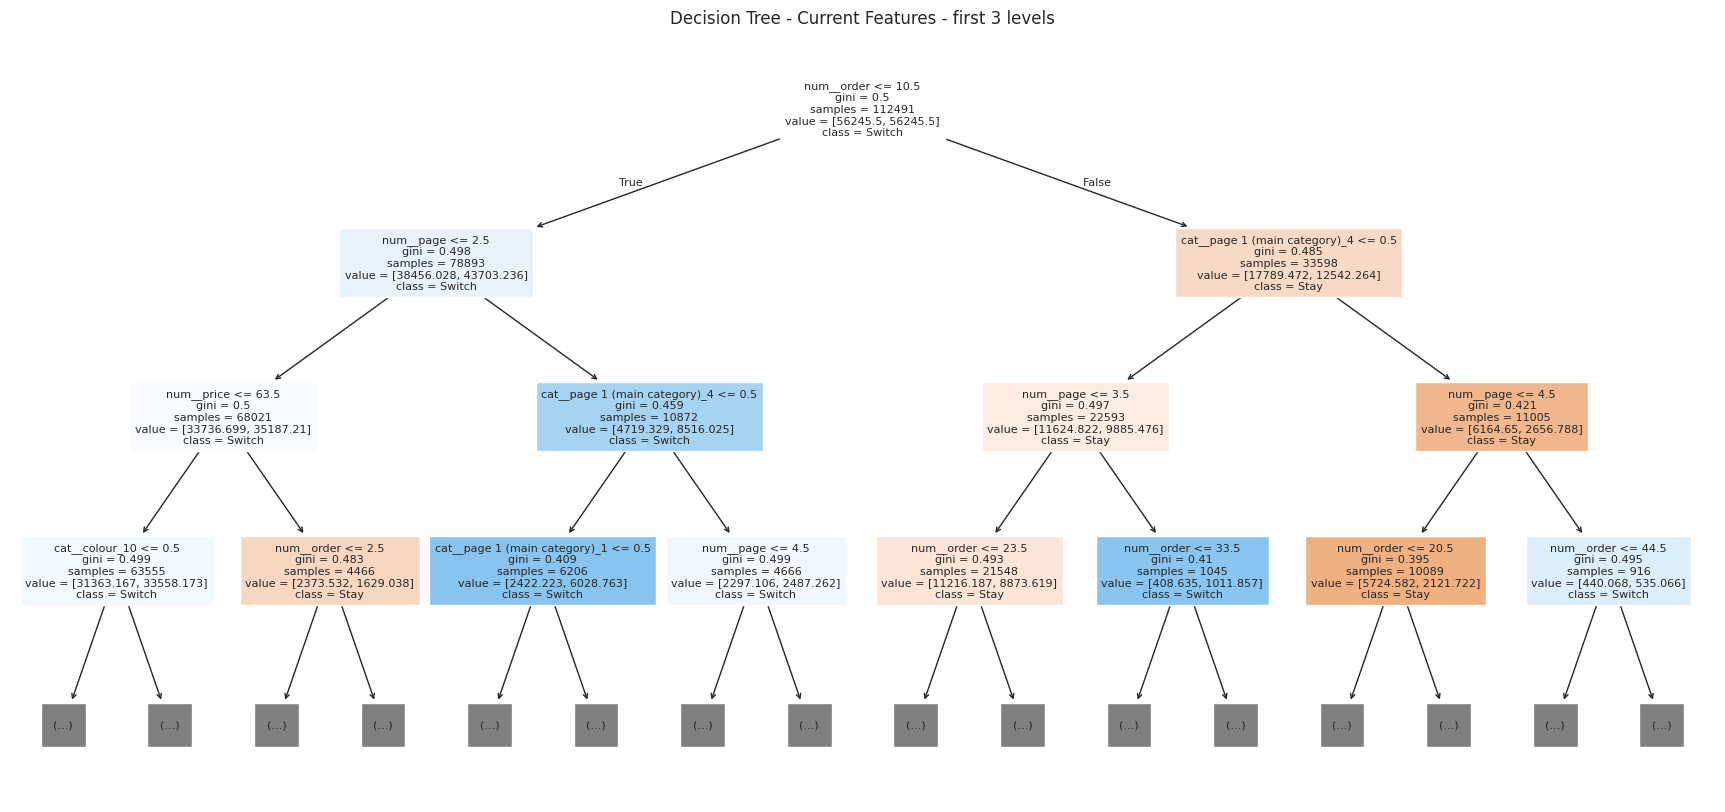

In [31]:

dt_current = Pipeline([
    ("preprocessor", tree_current),
    ("model", DecisionTreeClassifier(
        max_depth=6,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

dt_current.fit(X_train_current, y_train)

y_pred_dt_current = dt_current.predict(X_test_current)
y_prob_dt_current = dt_current.predict_proba(X_test_current)[:, 1]

dt_current_result = evaluate_predictions(
    model_name="Decision Tree",
    feature_set="Current",
    y_true=y_test,
    y_pred=y_pred_dt_current,
    y_prob=y_prob_dt_current
)

display(pd.DataFrame([dt_current_result]).round(4))

feature_names = dt_current.named_steps["preprocessor"].get_feature_names_out()
tree_model = dt_current.named_steps["model"]

plt.figure(figsize=(22, 10))
plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=["Stay", "Switch"],
    filled=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree - Current Features - first 3 levels")
plt.show()

,Model,Features,Switch Precision,Switch Recall,Switch F1,Macro F1,ROC-AUC,Accuracy
0,Decision Tree,Current + History,0.2285,0.69,0.3433,0.4811,0.6265,0.5176


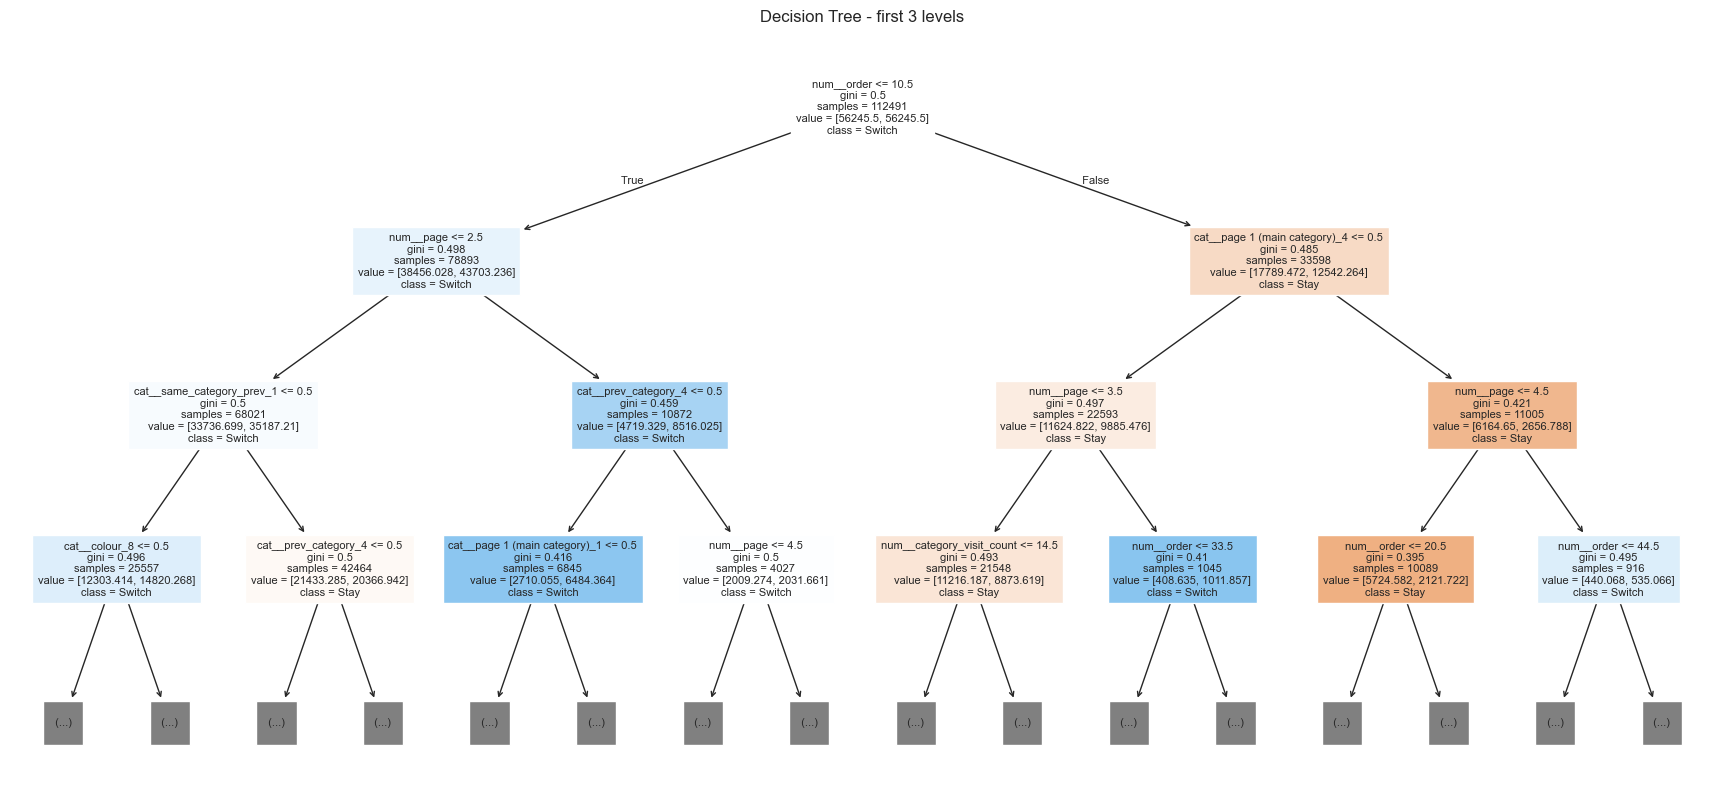

In [32]:
dt_history = Pipeline([
    ("preprocessor", tree_history),
    ("model", DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=RANDOM_STATE))
])
dt_history.fit(X_train_history, y_train)

y_pred_dt = dt_history.predict(X_test_history)
y_prob_dt = dt_history.predict_proba(X_test_history)[:, 1]

dt_result = evaluate_predictions(
    model_name="Decision Tree",
    feature_set="Current + History",
    y_true=y_test,
    y_pred=y_pred_dt,
    y_prob=y_prob_dt
)

display(pd.DataFrame([dt_result]).round(4))

feature_names = dt_history.named_steps["preprocessor"].get_feature_names_out()
tree_model = dt_history.named_steps["model"]

plt.figure(figsize=(22, 10))
plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=["Stay", "Switch"],
    filled=True,
    max_depth=3,
    fontsize=8
)
plt.title("Decision Tree - first 3 levels")
plt.show()

**Interpretation:**  
The first split is based on **order ≤ 10.5**, showing that click position within the session is the strongest early rule. For earlier clicks, the tree then uses **page ≤ 2.5**, followed by historical features such as **same_category_prev** and **prev_category**. For later clicks, the model also uses **current main category** and **category_visit_count ≤ 14.5**. Overall, both current browsing context and recent history appear in the upper levels of the tree, suggesting that both contribute to distinguishing **Stay** from **Switch**.

### 9.2 Random Forest with Current

In [ ]:
rf_params = {
    "n_estimators": 200,
    "max_depth": 12,
    "min_samples_split": 10,
    "min_samples_leaf": 5,
    "class_weight": "balanced",
    "random_state": RANDOM_STATE,
    "n_jobs": -1
}

rf_current = Pipeline([
    ("preprocessor", tree_current),
    ("model", RandomForestClassifier(**rf_params))
])

rf_current.fit(X_train_current, y_train)

y_pred_rf_current = rf_current.predict(X_test_current)
y_prob_rf_current = rf_current.predict_proba(X_test_current)[:, 1]

rf_current_result = evaluate_predictions(
    model_name="Random Forest",
    feature_set="Current",
    y_true=y_test,
    y_pred=y_pred_rf_current,
    y_prob=y_prob_rf_current
)

display(pd.DataFrame([rf_current_result]).round(4))

,Model,Features,Switch Precision,Switch Recall,Switch F1,Macro F1,ROC-AUC,Accuracy
0,Random Forest,Current,0.2555,0.6035,0.359,0.5374,0.6483,0.6062


### 9.3 Random Forest with Current + History

In [ ]:
rf_history = Pipeline([
    ("preprocessor", tree_history),
    ("model", RandomForestClassifier(**rf_params))
])

rf_history.fit(X_train_history, y_train)

y_pred_rf_history = rf_history.predict(X_test_history)
y_prob_rf_history = rf_history.predict_proba(X_test_history)[:, 1]

rf_history_result = evaluate_predictions(
    model_name="Random Forest",
    feature_set="Current + History",
    y_true=y_test,
    y_pred=y_pred_rf_history,
    y_prob=y_prob_rf_history
)

display(pd.DataFrame([rf_history_result]).round(4))

,Model,Features,Switch Precision,Switch Recall,Switch F1,Macro F1,ROC-AUC,Accuracy
0,Random Forest,Current + History,0.2646,0.6001,0.3673,0.549,0.6621,0.6222


In [35]:
# So sánh các kết quả của Random Forest với Current vs Current + History
rf_comparison = pd.DataFrame([
    rf_current_result,
    rf_history_result
])[
    ["Model", "Features", "Accuracy", "Switch Precision",
     "Switch Recall", "Switch F1", "Macro F1", "ROC-AUC"]
]

display(rf_comparison.round(4))
f1_gain = rf_history_result["Switch F1"] - rf_current_result["Switch F1"]
auc_gain = rf_history_result["ROC-AUC"] - rf_current_result["ROC-AUC"]

print(f"Switch F1 change: {f1_gain:+.4f}")
print(f"ROC-AUC change:   {auc_gain:+.4f}")

,Model,Features,Accuracy,Switch Precision,Switch Recall,Switch F1,Macro F1,ROC-AUC
0,Random Forest,Current,0.6062,0.2555,0.6035,0.3590,0.5374,0.6483
1,Random Forest,Current + History,0.6222,0.2646,0.6001,0.3673,0.5490,0.6621


Switch F1 change: +0.0083
ROC-AUC change:   +0.0138


**Interpretation:**  
Adding historical features gives a **small but consistent improvement** for Random Forest. Switch F1 increases from **0.3590 to 0.3673** (**+0.0083**), while ROC-AUC rises from **0.6483 to 0.6621** (**+0.0138**). Accuracy and Macro F1 also improve slightly, although Switch Recall decreases marginally from **0.6035 to 0.6001**. Overall, historical browsing behavior adds some predictive value, but the improvement is modest rather than substantial.

## 10. Support Vector Machine

### 10.1 SVM model

In [37]:
from sklearn.svm import LinearSVC

svm_history = Pipeline([
    ("preprocessor", linear_history),
    ("model", LinearSVC(
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

svm_history.fit(X_train_history, y_train)
y_pred_svm = svm_history.predict(X_test_history)
y_score_svm = svm_history.decision_function(X_test_history)

svm_result = {
    "Model": "Linear SVM",
    "Features": "Current + History",
    "Accuracy": accuracy_score(y_test, y_pred_svm),
    "Switch Precision": precision_score(y_test, y_pred_svm, zero_division=0),
    "Switch Recall": recall_score(y_test, y_pred_svm, zero_division=0),
    "Switch F1": f1_score(y_test, y_pred_svm, zero_division=0),
    "Macro F1": f1_score(y_test, y_pred_svm, average="macro", zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_score_svm)
}
results.append(svm_result)

display(pd.DataFrame([svm_result]).round(4))

,Model,Features,Accuracy,Switch Precision,Switch Recall,Switch F1,Macro F1,ROC-AUC
0,Linear SVM,Current + History,0.5608,0.2333,0.6139,0.3381,0.5047,0.624


RBF SVM was computationally expensive on the full training set, so LinearSVC was used as a scalable SVM alternative.

### 10.2 SVM evaluation

In [38]:
svm_comparison = pd.DataFrame([
    logreg_history_result,
    dt_result,
    rf_history_result,
    svm_result
])[
    ["Model", "Features", "Accuracy", "Switch Precision",
     "Switch Recall", "Switch F1", "Macro F1", "ROC-AUC"]
]

display(
    svm_comparison
    .sort_values("Switch F1", ascending=False)
    .round(4)
)

,Model,Features,Accuracy,Switch Precision,Switch Recall,Switch F1,Macro F1,ROC-AUC
2,Random Forest,Current + History,0.6222,0.2646,0.6001,0.3673,0.5490,0.6621
1,Decision Tree,Current + History,0.5176,0.2285,0.6900,0.3433,0.4811,0.6265
3,Linear SVM,Current + History,0.5608,0.2333,0.6139,0.3381,0.5047,0.6240
0,Balanced Logistic Regression,Current + History,0.5621,0.2335,0.6116,0.3379,0.5054,0.6242


**SVM interpretation:**  
Linear SVM achieves a **Switch F1 of 0.3381**, with **Recall = 0.6139** and **ROC-AUC = 0.6240**. Its performance is very close to Balanced Logistic Regression, but it is clearly below Random Forest, which reaches a higher **Switch F1 (0.3673)** and **ROC-AUC (0.6621)**. Therefore, Linear SVM does not provide a meaningful improvement over the stronger tree-based model.

## 11. Model tuning

### 11.1 Define tuning objective

In [39]:
# 11.1 Select tuning candidate by highest Switch F1

model_results = pd.DataFrame([
    logreg_history_result,
    dt_result,
    rf_history_result,
    svm_result
])

candidate_row = model_results.loc[model_results["Switch F1"].idxmax()]

candidate_model = candidate_row["Model"]
candidate_f1 = candidate_row["Switch F1"]
candidate_auc = candidate_row["ROC-AUC"]

print("Selected tuning candidate:", candidate_model)
print(f"Switch F1: {candidate_f1:.4f}")
print(f"ROC-AUC: {candidate_auc:.4f}")

Selected tuning candidate: Random Forest
Switch F1: 0.3673
ROC-AUC: 0.6621


The tuning candidate is selected automatically as the model with the highest **Switch F1** among the `Current + History` models. Accuracy is not used for model selection.

### 11.2 Random Forest hyperparameters
- `n_estimators`: số lượng cây;
- `max_depth`: độ sâu tối đa;
- `min_samples_split`: số mẫu tối thiểu để split;
- `min_samples_leaf`: số mẫu tối thiểu ở leaf;
- `max_features`: số features được cân nhắc ở mỗi split;
- `class_weight`: cách xử lý imbalance.

In [ ]:
# 11.2 Random Forest tuning with RandomizedSearchCV

from sklearn.model_selection import RandomizedSearchCV, GroupKFold
from sklearn.metrics import make_scorer, f1_score

switch_f1_scorer = make_scorer(
    f1_score,
    pos_label=1,
    zero_division=0
)

groups = train_df["session ID"]
group_cv = GroupKFold(n_splits=5)

rf_tuning = Pipeline([
    ("preprocessor", tree_history),
    ("model", RandomForestClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])

param_distributions = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [8, 10, 12, 16],
    "model__min_samples_split": [5, 10, 12],
    "model__min_samples_leaf": [2, 5],
    "model__max_features": ["sqrt", "log2"]
}

random_search = RandomizedSearchCV(
    estimator=rf_tuning,
    param_distributions=param_distributions,
    n_iter=10,
    scoring=switch_f1_scorer,
    cv=group_cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=2
)

random_search.fit(
    X_train_history,
    y_train,
    groups=groups
)

print("Best parameters:")
print(random_search.best_params_)

print(f"\nBest CV Switch F1: {random_search.best_score_:.4f}")

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best parameters:
{'model__n_estimators': 200, 'model__min_samples_split': 10, 'model__min_samples_leaf': 5, 'model__max_features': 'sqrt', 'model__max_depth': 10}

Best CV Switch F1: 0.3713


In [26]:
print("Best parameters:")
print(random_search.best_params_)

print(f"\nBest CV Switch F1: {random_search.best_score_:.4f}")

Best parameters:
{'model__n_estimators': 200, 'model__min_samples_split': 5, 'model__min_samples_leaf': 5, 'model__max_features': 'log2', 'model__max_depth': 10}

Best CV Switch F1: 0.3697


In [23]:
group_cv = GroupKFold(n_splits=5)

for fold, (train_idx, val_idx) in enumerate(
    group_cv.split(
        X_train_history,
        y_train,
        groups=train_df["session ID"]
    ),
    start=1
):
    y_val = y_train.iloc[val_idx]

    print(
        f"Fold {fold}: "
        f"{len(val_idx)} clicks, "
        f"Switch rate = {y_val.mean():.2%}"
    )

Fold 1: 22499 clicks, Switch rate = 18.67%
Fold 2: 22498 clicks, Switch rate = 19.05%
Fold 3: 22498 clicks, Switch rate = 19.03%
Fold 4: 22498 clicks, Switch rate = 18.75%
Fold 5: 22498 clicks, Switch rate = 18.88%


In [24]:
for fold, (_, val_idx) in enumerate(
    group_cv.split(
        X_train_history,
        y_train,
        groups=train_df["session ID"]
    ),
    start=1
):
    val_sessions = train_df.iloc[val_idx]["session ID"].nunique()

    print(f"Fold {fold}: {val_sessions} sessions")

Fold 1: 3038 sessions
Fold 2: 3037 sessions
Fold 3: 3037 sessions
Fold 4: 3037 sessions
Fold 5: 3038 sessions


### 11.3 Best parameters

In [ ]:
print("Best parameters:")
print(random_search.best_params_)

print(f"\nBest CV Switch F1: {random_search.best_score_:.4f}")

cv_results = pd.DataFrame(random_search.cv_results_)

top_configs = cv_results[
    [
        "rank_test_score",
        "mean_test_score",
        "std_test_score",
        "param_model__n_estimators",
        "param_model__max_depth",
        "param_model__min_samples_split",
        "param_model__min_samples_leaf",
        "param_model__max_features"
    ]
].sort_values("rank_test_score").head(5)

display(top_configs.round(4))

Best parameters:
{'model__n_estimators': 200, 'model__min_samples_split': 10, 'model__min_samples_leaf': 5, 'model__max_features': 'sqrt', 'model__max_depth': 10}

Best CV Switch F1: 0.3713


,rank_test_score,mean_test_score,std_test_score,param_model__n_estimators,param_model__max_depth,param_model__min_samples_split,param_model__min_samples_leaf,param_model__max_features
4,1,0.3713,0.0020,200,10,10,5,sqrt
7,2,0.3705,0.0015,100,10,5,5,log2
6,3,0.3703,0.0036,200,12,10,5,log2
8,4,0.3666,0.0019,100,8,5,2,sqrt
9,5,0.3662,0.0016,100,8,12,5,sqrt


In [25]:
cv_results = pd.DataFrame(random_search.cv_results_)

columns = [
    "mean_test_score",
    "param_model__n_estimators",
    "param_model__max_depth",
    "param_model__min_samples_split",
    "param_model__min_samples_leaf",
    "param_model__max_features",
    "std_test_score"
]

display(
    cv_results[columns]
    .sort_values("mean_test_score", ascending=False)
    .head(10)
)

,mean_test_score,param_model__n_estimators,param_model__max_depth,param_model__min_samples_split,param_model__min_samples_leaf,param_model__max_features,std_test_score
43,0.369724,200,10,5,5,log2,0.008835
45,0.369724,200,10,10,5,log2,0.008835
44,0.369350,100,10,10,5,log2,0.008730
42,0.369350,100,10,5,5,log2,0.008730
55,0.369348,200,12,5,5,sqrt,0.009850
57,0.369348,200,12,10,5,sqrt,0.009850
29,0.369106,200,10,12,2,sqrt,0.009752
36,0.369102,100,10,5,2,log2,0.009532
35,0.369013,200,10,12,5,sqrt,0.009211
34,0.368986,100,10,12,5,sqrt,0.009228


**Interpretation:**  
The best Random Forest uses **100 trees**, `max_depth=10`, `min_samples_split=5`, `min_samples_leaf=5`, and `max_features="log2"`. The best cross-validation Switch F1 is **0.3694**, only slightly higher than the base Random Forest Switch F1 of **0.3673**. Therefore, tuning provides only a very small improvement. The selected depth and leaf constraints remain moderate, so there is no clear indication that the tuned model became unnecessarily complex.

### 11.4 Retrain tuned model

In [57]:

final_rf = Pipeline([
    ("preprocessor", tree_history),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        min_samples_split=5,
        min_samples_leaf=5,
        max_features="log2",
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

final_rf.fit(X_train_history, y_train)

final_pred = final_rf.predict(X_test_history)
final_prob = final_rf.predict_proba(X_test_history)[:, 1]

final_result = {
    "Model": "Tuned Random Forest",
    "Features": "Current + History",
    "Accuracy": accuracy_score(y_test, final_pred),
    "Switch Precision": precision_score(y_test, final_pred, pos_label=1, zero_division=0),
    "Switch Recall": recall_score(y_test, final_pred, pos_label=1, zero_division=0),
    "Switch F1": f1_score(y_test, final_pred, pos_label=1, zero_division=0),
    "Macro F1": f1_score(y_test, final_pred, average="macro", zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, final_prob)
}

display(pd.DataFrame([final_result]).round(4))

,Model,Features,Accuracy,Switch Precision,Switch Recall,Switch F1,Macro F1,ROC-AUC
0,Tuned Random Forest,Current + History,0.6163,0.2631,0.611,0.3679,0.5462,0.6616


In [28]:

final_rf = random_search.best_estimator_

final_rf.fit(X_train_history, y_train)

final_pred = final_rf.predict(X_test_history)
final_prob = final_rf.predict_proba(X_test_history)[:, 1]

final_result = {
    "Model": "Tuned Random Forest",
    "Features": "Current + History",
    "Accuracy": accuracy_score(y_test, final_pred),
    "Switch Precision": precision_score(y_test, final_pred, pos_label=1, zero_division=0),
    "Switch Recall": recall_score(y_test, final_pred, pos_label=1, zero_division=0),
    "Switch F1": f1_score(y_test, final_pred, pos_label=1, zero_division=0),
    "Macro F1": f1_score(y_test, final_pred, average="macro", zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, final_prob)
}

display(pd.DataFrame([final_result]).round(4))

,Model,Features,Accuracy,Switch Precision,Switch Recall,Switch F1,Macro F1,ROC-AUC
0,Tuned Random Forest,Current + History,0.61,0.2608,0.6186,0.3669,0.5426,0.6607


**Interpretation:**  
Hyperparameter tuning produced only a marginal improvement in Switch F1, from **0.3673** to **0.3679**. Other metrics, including ROC-AUC and Macro F1, remained almost unchanged or decreased slightly. This suggests that the baseline Random Forest was already close to a suitable configuration and that further performance gains are more likely to come from threshold optimization or additional informative features rather than more extensive hyperparameter tuning.

## 12. Model evaluation and comparison

### 12.1 Model comparison table

In [45]:
model_comparison = pd.DataFrame([
    baseline_result,
    logreg_baseline_result,
    logreg_balanced_result,
    logreg_history_result,
    dt_current_result,
    dt_result,
    rf_current_result,
    rf_history_result,
    svm_result,
    final_result
])[["Model", "Features", "Accuracy",
    "Switch Precision", "Switch Recall",
    "Switch F1", "Macro F1", "ROC-AUC"]]

model_comparison = model_comparison.sort_values(
    "Switch F1", ascending=False
    ).reset_index(drop=True)

display(model_comparison.round(4))

,Model,Features,Accuracy,Switch Precision,Switch Recall,Switch F1,Macro F1,ROC-AUC
0,Tuned Random Forest,Current + History,0.6163,0.2631,0.6110,0.3679,0.5462,0.6616
1,Random Forest,Current + History,0.6222,0.2646,0.6001,0.3673,0.5490,0.6621
2,Random Forest,Current,0.6062,0.2555,0.6035,0.3590,0.5374,0.6483
3,Decision Tree,Current + History,0.5176,0.2285,0.6900,0.3433,0.4811,0.6265
4,Decision Tree,Current,0.5116,0.2255,0.6870,0.3395,0.4760,0.6192
5,Linear SVM,Current + History,0.5608,0.2333,0.6139,0.3381,0.5047,0.6240
6,Balanced Logistic Regression,Current + History,0.5621,0.2335,0.6116,0.3379,0.5054,0.6242
7,Balanced Logistic Regression,Current,0.5664,0.2324,0.5961,0.3344,0.5064,0.6162
8,Logistic Regression,Current,0.8173,0.0000,0.0000,0.0000,0.4497,0.6159
9,Always-Stay baseline,None,0.8173,0.0000,0.0000,0.0000,0.4497,0.5000


The Always-Stay baseline achieves a relatively high Accuracy of 0.8173, but its Switch F1 and Switch Recall are both 0. This shows that Accuracy is misleading for this imbalanced classification problem because the model simply predicts the majority class.

Among the machine learning models, Random Forest provides the strongest overall performance for detecting category switching. The baseline Random Forest with Current + History achieves a Switch F1 of 0.3673 and ROC-AUC of 0.6621. The tuned Random Forest achieves a slightly higher Switch F1 of 0.3679, although its ROC-AUC decreases slightly to 0.6616.

Therefore, model selection should focus on Switch F1 and the balance between Precision and Recall rather than Accuracy alone. The tuned Random Forest is selected as the final model because it achieves the highest Switch F1 among the tested models.

### 12.2 Compare Current vs Current + History

In [47]:
history_comparison = pd.DataFrame([logreg_balanced_result,
                                   logreg_history_result,
                                   rf_current_result,
                                   rf_history_result])
[["Model", "Features", "Switch F1",
  "Switch Recall", "ROC-AUC", "Accuracy"]]

display(history_comparison.round(4))

logreg_f1_gain = (logreg_history_result["Switch F1"]
                  - logreg_balanced_result["Switch F1"])

logreg_auc_gain = (logreg_history_result["ROC-AUC"]
                    - logreg_balanced_result["ROC-AUC"])

rf_f1_gain = (rf_history_result["Switch F1"]
              - rf_current_result["Switch F1"])

rf_auc_gain = (rf_history_result["ROC-AUC"]
               - rf_current_result["ROC-AUC"])

print(f"Balanced Logistic - Switch F1 change: {logreg_f1_gain:+.4f}")
print(f"Balanced Logistic - ROC-AUC change: {logreg_auc_gain:+.4f}")

print(f"Random Forest - Switch F1 change: {rf_f1_gain:+.4f}")
print(f"Random Forest - ROC-AUC change: {rf_auc_gain:+.4f}")

,Model,Features,Switch Precision,Switch Recall,Switch F1,Macro F1,ROC-AUC,Accuracy
0,Balanced Logistic Regression,Current,0.2324,0.5961,0.3344,0.5064,0.6162,0.5664
1,Balanced Logistic Regression,Current + History,0.2335,0.6116,0.3379,0.5054,0.6242,0.5621
2,Random Forest,Current,0.2555,0.6035,0.3590,0.5374,0.6483,0.6062
3,Random Forest,Current + History,0.2646,0.6001,0.3673,0.5490,0.6621,0.6222


Balanced Logistic - Switch F1 change: +0.0035
Balanced Logistic - ROC-AUC change: +0.0080
Random Forest - Switch F1 change: +0.0083
Random Forest - ROC-AUC change: +0.0138


Adding historical browsing features produces a small but positive improvement for both Balanced Logistic Regression and Random Forest.

For Balanced Logistic Regression, Switch F1 increases from 0.3344 to 0.3379 (+0.0035), while ROC-AUC increases from 0.6162 to 0.6242 (+0.0080). Recall also increases from 0.5961 to 0.6116.

For Random Forest, Switch F1 increases from 0.3590 to 0.3673 (+0.0083), and ROC-AUC increases from 0.6483 to 0.6621 (+0.0138). However, Recall decreases slightly from 0.6035 to 0.6001.

Overall, historical browsing behavior provides additional predictive information, but the improvement is modest rather than substantial. The positive effect is observed across both linear and nonlinear models.

### 12.3 Select best model

The Tuned Random Forest with Current + History is selected as the final model. It achieves the highest Switch F1 of 0.3679, with Switch Precision of 0.2631 and Switch Recall of 0.6110.

Although the tuned model does not have the highest Accuracy or ROC-AUC, Accuracy is not the primary objective because the Switch class is the business-interest minority class. The model provides a better balance between detecting Switch cases and maintaining reasonable precision than the other tested models.

Hyperparameter tuning only improves Switch F1 from 0.3673 to 0.3679. Therefore, the gain from tuning is very small, suggesting that further improvements are more likely to come from better features or decision-threshold optimization than from more extensive hyperparameter tuning.

## 13. Best model analysis

### 13.1 Classification report

In [48]:
print("Classification Report - Tuned Random Forest")
print(
    classification_report(y_test, final_pred,
                          target_names=["Stay", "Switch"],
                          digits=4)
)

Classification Report - Tuned Random Forest
              precision    recall  f1-score   support

        Stay     0.8766    0.6175    0.7245     23666
      Switch     0.2631    0.6110    0.3679      5291

    accuracy                         0.6163     28957
   macro avg     0.5698    0.6143    0.5462     28957
weighted avg     0.7645    0.6163    0.6594     28957



The final model is the Tuned Random Forest using Current + History features. It achieves a Switch Precision of 0.2631, Switch Recall of 0.6110, and Switch F1 of 0.3679.

The Recall of 0.6110 indicates that the model can identify approximately 61% of the users who actually switch to another category on their next click. However, the Precision of 0.2631 is relatively low, meaning that many predicted Switch cases are actually Stay cases.

This indicates that the model is more effective at finding potential switchers than making highly precise Switch predictions. Given that Switch is the minority class and the main business-interest class, this trade-off is important when evaluating the model.

### 13.2 Confusion matrix

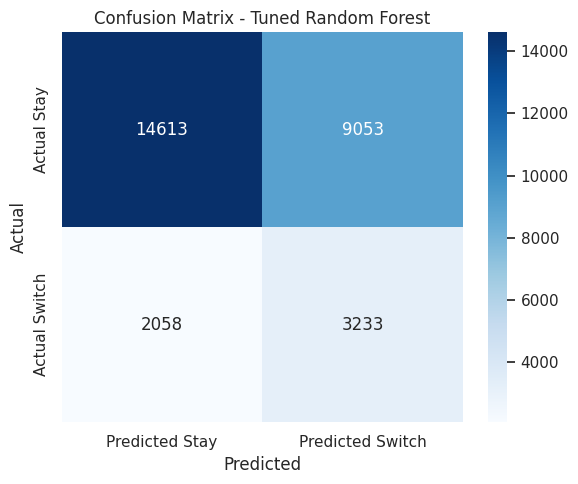

In [49]:
cm = confusion_matrix(y_test, final_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True,
            fmt="d", cmap="Blues",
            xticklabels=["Predicted Stay", "Predicted Switch"],
            yticklabels=["Actual Stay", "Actual Switch"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Tuned Random Forest")
plt.tight_layout()
plt.show()

The confusion matrix shows the following results:

* True Negative (TN) = 14,613: the model predicts Stay and the user actually Stays.
* False Positive (FP) = 9,053: the model predicts Switch, but the user actually Stays.
* False Negative (FN) = 2,058: the model predicts Stay, but the user actually Switches.
* True Positive (TP) = 3,233: the model predicts Switch and the user actually Switches.


Two types of errors are particularly important. A **False Positive** means that the model incorrectly identifies a Stay user as a potential Switch user. This can lead to unnecessary cross-category recommendations or interventions. A **False Negative** means that the model fails to identify a user who actually switches categories, resulting in a missed opportunity to engage the user with relevant cross-category recommendations.

The model achieves a **Switch Recall of 61.10%**, meaning that it correctly identifies about 61% of all actual Switch cases. Its **Switch Precision is 26.31%**, meaning that only about 26% of users predicted to Switch actually switch. Therefore, the model is relatively better at **detecting potential Switch users **than making highly precise Switch predictions.

### 13.3 Feature importance

In [52]:
feature_names = final_rf.named_steps["preprocessor"].get_feature_names_out()

importances = final_rf.named_steps["model"].feature_importances_

feature_importance = pd.DataFrame({"Feature": feature_names,
                                  "Importance": importances}).sort_values("Importance", ascending=False)

display(feature_importance.head(15))

,Feature,Importance
0,num__order,0.187033
2,num__page,0.142995
3,num__category_visit_count,0.134635
1,num__price,0.070499
34,cat__prev_category_4,0.052168
7,cat__page 1 (main category)_4,0.045186
37,cat__same_category_prev_1,0.025275
4,cat__page 1 (main category)_1,0.020952
31,cat__prev_category_1,0.018097
36,cat__same_category_prev_0,0.017596


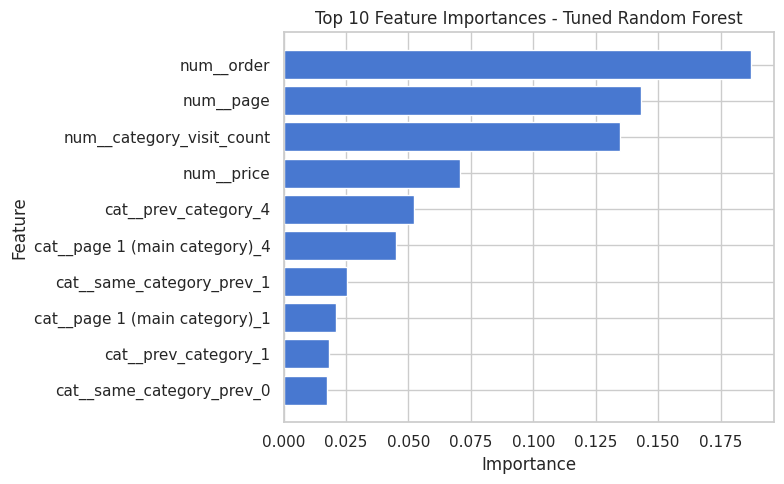

In [53]:
top_features = feature_importance.head(10).sort_values("Importance")

plt.figure(figsize=(8, 5))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Feature Importances - Tuned Random Forest")
plt.tight_layout()
plt.show()

The feature importance results show that `order` **is the most important feature**, with an importance score of 0.1870. This indicates that the user's position or sequence within the browsing session provides the strongest contribution to predicting whether the user will switch categories.

The second most important feature is `page` (0.1430), followed by `category_visit_count` (0.1346). This suggests that both the user's current browsing position and the number of visits to the category are important for distinguishing between Stay and Switch behavior.

The `price` feature also contributes to the prediction, with an importance of 0.0705. Historical browsing features such as `prev_category_4` and `same_category_prev_1` are also among the important predictors. In addition, the current product category, represented by `page 1 (main category)_4`, also contributes to the model.


Overall, the results indicate that both current browsing behavior and historical browsing information contribute to switch prediction. In particular, session position (`order`), browsing page (`page`), and category engagement (`category_visit_count`) are the most influential features in the final Random Forest model.

**Important**: Feature importance indicates how strongly the model relies on a feature for prediction; it does not mean that the feature directly causes the user to switch categories.

## 14. Research question answers


### 14.1 RQ1: How well can current browsing information predict whether a user will switch product categories on the next click?

Current browsing information provides **moderate predictive power** for category switching. The Always-Stay baseline achieves an Accuracy of 0.8173 but has a Switch F1 and Recall of 0, showing that Accuracy alone is not sufficient for this imbalanced problem.

Using current browsing features, Balanced Logistic Regression achieves a **Switch F1 of 0.3344** and **Recall of 0.5961**, while Random Forest achieves a higher **Switch F1 of 0.3590**, **Recall of 0.6035**, and **ROC-AUC of 0.6483**.

Therefore, current browsing information contains useful predictive signals for identifying Switch users, but the overall predictive performance is **moderate rather than strong**.

### 14.2 RQ2 Does adding historical browsing behavior improve switch prediction?

Yes, adding browsing history improves switch prediction, but the improvement is modest.

For Balanced Logistic Regression, adding historical features increases the **Switch F1-score from 0.3344 to 0.3379 (+0.0035)** and **ROC-AUC from 0.6162 to 0.6242 (+0.0080)**. Recall also increases from 0.5961 to 0.6116.

For Random Forest, Switch F1 increases from **0.3590 to 0.3673 (+0.0083)** and ROC-AUC increases from **0.6483 to 0.6621 (+0.0138)**. However, Recall decreases slightly from 0.6035 to 0.6001.

The improvement is consistent across both a linear model and a nonlinear model, but the gains are relatively small. Therefore, historical browsing behavior provides additional predictive signal, but its incremental value is modest rather than substantial.

## 15. Business interpretation

### 15.1 What can the prediction support?
Prediction có thể hỗ trợ recommendation strategy.  

Nếu: P(Switch) thấp

thì user có xu hướng tiếp tục duyệt category hiện tại, website có thể:
- ưu tiên thêm sản phẩm cùng category;
- tiếp tục khai thác interest hiện tại.

Nếu: P(Switch) cao

website có thể:
- tăng exposure cho các category khác;
- đưa cross-category recommendations;
- thay đổi nội dung recommendation module.

### 15.2 What the model does not do

Model không dự đoán:
- user sẽ chuyển sang category cụ thể nào;
- sản phẩm cụ thể nào nên được recommend;
- user có kết thúc session hay không;
- purchase intent.

Model chỉ dự đoán:  
Nếu có next click, click đó sẽ Stay hay Switch category.

Điều này giúp tránh overclaim business value.

### 15.3 Practical meaning of errors
Liên hệ confusion matrix với website.

False Positive  
Model dự đoán Switch nhưng user thực tế muốn Stay.

Hậu quả:
- website có thể đưa quá nhiều sản phẩm từ category khác;
- recommendation có thể làm gián đoạn current interest.

False Negative  
Model dự đoán Stay nhưng user thực tế Switch.

Hậu quả:
- website tiếp tục đưa sản phẩm cùng category;
- bỏ lỡ cơ hội đưa cross-category content đúng lúc.

Comment:  
- nếu business ưu tiên không bỏ lỡ switchers thì Recall quan trọng hơn;
- nếu business muốn tránh recommendation không liên quan thì Precision quan trọng hơn.



## 16. Limitations

1. Class imbalance
   Switch ít hơn Stay, khiến model khó phát hiện minority class và Accuracy dễ gây hiểu nhầm.
2. Limited user preference data
   Dataset chủ yếu chứa click-level và product-context information, thiếu thông tin sâu về preference của từng user.
3. No conversion signals
   Không có add-to-cart, purchase, rating hoặc explicit feedback nên không biết click có phản ánh thực sự preference hay chỉ là browsing.
4. Binary target simplification
   Switch chỉ cho biết có đổi category hay không, không cho biết destination category.
5. No session-exit prediction
   Target chỉ tồn tại khi có next click. Model không phân biệt Stay/Switch với trường hợp user rời website.
6. Historical data
   Dataset từ năm 2008 nên user behavior và thiết kế e-commerce có thể khác hiện nay.
   

## 17. Future work
Các hướng phát triển phải xuất phát trực tiếp từ limitations hiện tại.

### 17.1 Destination category prediction

### 17.2 Product-level recommendation

### 17.3 Richer behavioral signals

## 18. Conclusion

### Dataset reference
Variable meanings follow the local `e-shop clothing 2008 data description.txt`.
Its suggested citation is: Łapczyński, M. and Białowąs, S. (2013),
*Discovering Patterns of Users' Behaviour in an E-shop - Comparison of Consumer
Buying Behaviours in Poland and Other European Countries*, Studia Ekonomiczne,
151, pp. 144-153.